In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm


# ----------------------------------------------------------------------
# Estrategias (todas vectorizadas sobre simulaciones)
# ----------------------------------------------------------------------

class Strategy:
    def run(self, **kwargs):
        raise NotImplementedError


class ADRStrategy(Strategy):
    """
    Advección-Difusión-Reacción 1D vectorizada sobre simulaciones.
    Acepta D, v, k escalares o arrays de tamaño nsims.
    Devuelve 'concentration' con shape (nsims, nx), o (nx,) si nsims==1.
    """
    def run(self, D, v, k, L=500, T=365, dx=5, dt=0.1, C0=1.0):
        D = np.maximum(np.atleast_1d(np.asarray(D, dtype=float)), 0.0)
        v = np.maximum(np.atleast_1d(np.asarray(v, dtype=float)), 0.0)
        k = np.maximum(np.atleast_1d(np.asarray(k, dtype=float)), 0.0)

        nsims = max(D.size, v.size, k.size)
        D = np.broadcast_to(D, (nsims,)).astype(float)
        v = np.broadcast_to(v, (nsims,)).astype(float)
        k = np.broadcast_to(k, (nsims,)).astype(float)

        nx = int(L / dx) + 1
        nt = int(T / dt) + 1
        x = np.linspace(0, L, nx)

        # Coeficientes por simulación, con eje extra para broadcasting: (nsims, 1)
        a = (D * dt / dx**2)[:, None]
        b = (v * dt / dx)[:, None]
        c = (k * dt)[:, None]

        C = np.zeros((nsims, nx))
        C[:, 0] = C0

        for _ in range(nt):
            C_new = np.zeros_like(C)
            C_new[:, 1:-1] = (
                C[:, 1:-1]
                + a * (C[:, 2:] - 2.0 * C[:, 1:-1] + C[:, :-2])
                - b * (C[:, 1:-1] - C[:, :-2])
                - c * C[:, 1:-1]
            )
            np.maximum(C_new, 0.0, out=C_new)
            C_new[:, 0] = C0
            C = C_new

        return {
            "x": x,
            "concentration": C if nsims > 1 else C[0],
            "D": D, "v": v, "k": k
        }


class NitrateStrategy(ADRStrategy):
    pass


class IrrigationStrategy(Strategy):
    """Humedad vectorizada sobre simulaciones."""
    def run(self, I, C, ET, days=30, frequency=1, area=100, depth=1):
        I  = np.maximum(np.atleast_1d(np.asarray(I,  dtype=float)), 0.0)
        C  = np.maximum(np.atleast_1d(np.asarray(C,  dtype=float)), 0.0)
        ET = np.maximum(np.atleast_1d(np.asarray(ET, dtype=float)), 0.0)

        nsims = max(I.size, C.size, ET.size)
        I  = np.broadcast_to(I,  (nsims,)).astype(float)
        C  = np.broadcast_to(C,  (nsims,)).astype(float)
        ET = np.broadcast_to(ET, (nsims,)).astype(float)

        irrigation_input = I / 24.0
        capacity = C * depth * 1000.0

        moisture = np.zeros(nsims)
        series = np.zeros((nsims, days))

        for day in range(1, days + 1):
            if (day - 1) % frequency == 0:
                moisture = moisture + irrigation_input
            moisture = np.maximum(moisture - ET, 0.0)
            moisture = np.minimum(moisture, capacity)
            series[:, day - 1] = moisture

        return {
            "days": np.arange(1, days + 1),
            "moisture": series if nsims > 1 else series[0],
            "frequency": frequency, "area": area, "depth": depth
        }


class WheatStrategy(Strategy):
    """Producción vectorizada sobre simulaciones."""
    def run(self, P, R, WUE, area=50, days=120):
        P   = np.maximum(np.atleast_1d(np.asarray(P,   dtype=float)), 0.0)
        R   = np.maximum(np.atleast_1d(np.asarray(R,   dtype=float)), 0.0)
        WUE = np.maximum(np.atleast_1d(np.asarray(WUE, dtype=float)), 0.0)

        nsims = max(P.size, R.size, WUE.size)
        P   = np.broadcast_to(P,   (nsims,)).astype(float)
        R   = np.broadcast_to(R,   (nsims,)).astype(float)
        WUE = np.broadcast_to(WUE, (nsims,)).astype(float)

        months = max(int(np.ceil(days / 30)), 1)
        precipitation = P * months
        radiation = R * days
        water = precipitation * 0.001 * area * 10000.0
        production = water * WUE * (radiation / (20.0 * days if days else 1.0))

        return {
            "production": production if nsims > 1 else production[0],
            "precipitation": precipitation,
            "radiation": radiation,
            "WUE": WUE, "area": area, "days": days
        }


# ----------------------------------------------------------------------
# Facade Monte Carlo
# ----------------------------------------------------------------------

class MonteCarloFacade:
    def __init__(self, strategy=None, simulations=1000, seed=None, **defaults):
        self.strategy = strategy
        self.simulations = int(simulations)
        self.rng = np.random.default_rng(seed)
        self.defaults = defaults

    # ---------- muestreo (una sola vez, vectorizado) ----------
    def _sample(self, value, n=None):
        n = n or self.simulations
        if callable(value):
            return np.asarray([value() for _ in range(n)], dtype=float)
        if isinstance(value, dict):
            dist = value.get("distribution", "normal").lower()
            if dist == "normal":
                return self.rng.normal(value["mean"], value["std"], n)
            if dist == "uniform":
                return self.rng.uniform(value["low"], value["high"], n)
            if dist == "lognormal":
                return self.rng.lognormal(value["mean"], value["sigma"], n)
            if dist == "constant":
                return np.full(n, value["value"], dtype=float)
            raise ValueError("Distribución no soportada")
        if np.isscalar(value):
            return np.full(n, float(value))
        values = np.asarray(value, dtype=float)
        if values.size == 1:
            return np.full(n, float(values[0]))
        if values.size == n:
            return values
        return self.rng.choice(values, size=n, replace=True)

    # ---------- resolve (una sola llamada a la estrategia) ----------
    def resolve(self, strategy=None, **params):
        strategy = strategy or self.strategy
        if isinstance(strategy, str):
            strategies = {
                "adr":       ADRStrategy(),
                "nitrate":   NitrateStrategy(),
                "irrigation": IrrigationStrategy(),
                "wheat":     WheatStrategy()
            }
            strategy = strategies[strategy]

        params = {**self.defaults, **params}

        scalar_keys = {"L", "T", "dx", "dt", "C0",
                       "days", "frequency", "area", "depth"}
        sampled = {k: v for k, v in params.items() if k not in scalar_keys}
        fixed   = {k: v for k, v in params.items() if k in scalar_keys}

        samples = {k: self._sample(v) for k, v in sampled.items()}

        # ⚡ UNA sola llamada, todas las simulaciones a la vez
        result = strategy.run(**samples, **fixed)
        return self._aggregate_batch(result)

    # ---------- agregación sobre el lote completo ----------
    def _aggregate_batch(self, result):
        if "concentration" in result:
            matrix = np.asarray(result["concentration"])
            if matrix.ndim == 1:
                matrix = matrix[None, :]
            return {
                "x": result["x"],
                "results": matrix,
                "mean": matrix.mean(axis=0),
                "std":  matrix.std(axis=0),
                "p05":  np.percentile(matrix, 5,  axis=0),
                "p50":  np.percentile(matrix, 50, axis=0),
                "p95":  np.percentile(matrix, 95, axis=0),
            }

        if "moisture" in result:
            matrix = np.asarray(result["moisture"])
            if matrix.ndim == 1:
                matrix = matrix[None, :]
            return {
                "days": result["days"],
                "results": matrix,
                "mean": matrix.mean(axis=0),
                "std":  matrix.std(axis=0),
                "p05":  np.percentile(matrix, 5,  axis=0),
                "p50":  np.percentile(matrix, 50, axis=0),
                "p95":  np.percentile(matrix, 95, axis=0),
            }

        if "production" in result:
            values = np.atleast_1d(np.asarray(result["production"], dtype=float))
            return {
                "results": values,
                "mean": float(values.mean()),
                "std":  float(values.std()),
                "p05":  float(np.percentile(values, 5)),
                "p50":  float(np.percentile(values, 50)),
                "p95":  float(np.percentile(values, 95)),
            }

        return result

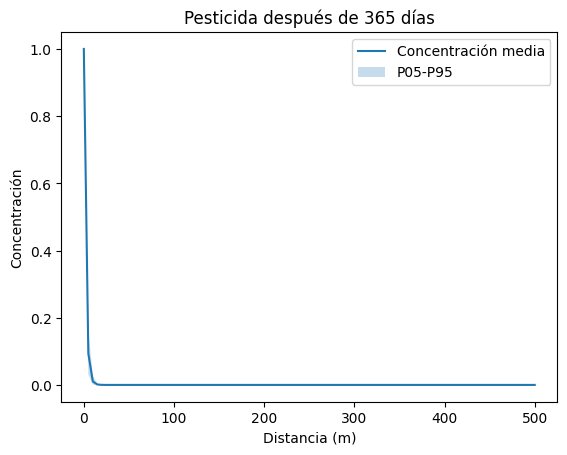

In [ ]:

mc = MonteCarloFacade(simulations=1000, seed=42)

resultado = mc.resolve(
    strategy="adr",
    D={"distribution": "normal", "mean": 0.01, "std": 0.005},
    v={"distribution": "normal", "mean": 0.05, "std": 0.02},
    k={"distribution": "normal", "mean": 0.1, "std": 0.02},
    L=500,
    T=365,
    dx=5,
    dt=0.1,
    C0=1
)

plt.plot(resultado["x"], resultado["mean"], label="Concentración media")
plt.fill_between(resultado["x"], resultado["p05"], resultado["p95"], alpha=0.25, label="P05-P95")
plt.xlabel("Distancia (m)")
plt.ylabel("Concentración")
plt.title("Pesticida después de 365 días")
plt.legend()
plt.show()

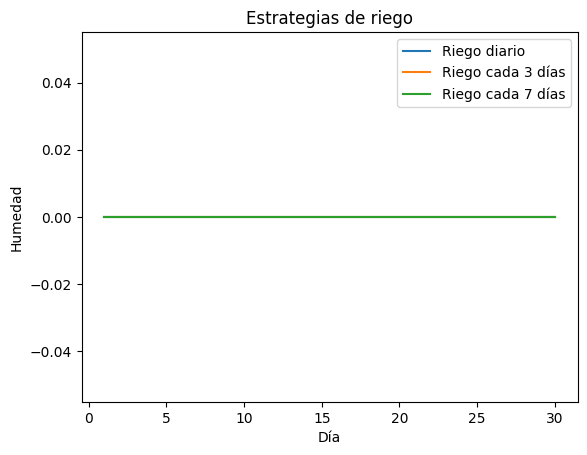

In [ ]:
estrategias = {
    "Riego diario": 1,
    "Riego cada 3 días": 3,
    "Riego cada 7 días": 7
}

resultados_riego = {}

for nombre, frecuencia in estrategias.items():
    resultados_riego[nombre] = mc.resolve(
        strategy="irrigation",
        I={"distribution": "normal", "mean": 10, "std": 2},
        C={"distribution": "normal", "mean": 0.2, "std": 0.05},
        ET={"distribution": "normal", "mean": 5, "std": 1},
        days=30,
        frequency=frecuencia,
        area=100,
        depth=1
    )

for nombre, resultado in resultados_riego.items():
    plt.plot(resultado["days"], resultado["mean"], label=nombre)

plt.xlabel("Día")
plt.ylabel("Humedad")
plt.title("Estrategias de riego")
plt.legend()
plt.show()

In [ ]:
resultado_nitratos = mc.resolve(
    strategy="nitrate",
    D={"distribution": "normal", "mean": 0.05, "std": 0.01},
    v={"distribution": "normal", "mean": 0.1, "std": 0.02},
    k={"distribution": "normal", "mean": 0.02, "std": 0.005},
    L=300,
    T=180,
    dx=5,
    dt=0.1,
    C0=1
)

plt.plot(resultado_nitratos["x"], resultado_nitratos["mean"], label="Concentración media")
plt.fill_between(resultado_nitratos["x"], resultado_nitratos["p05"], resultado_nitratos["p95"], alpha=0.25, label="P05-P95")
plt.xlabel("Distancia (m)")
plt.ylabel("Concentración")
plt.title("Contaminación por nitratos después de 180 días")
plt.legend()
plt.show()

In [ ]:
resultado_trigo = mc.resolve(
    strategy="wheat",
    P={"distribution": "normal", "mean": 50, "std": 20},
    R={"distribution": "normal", "mean": 20, "std": 5},
    WUE={"distribution": "normal", "mean": 1.5, "std": 0.3},
    area=50,
    days=120
)

print("Producción media:", resultado_trigo["mean"])
print("Desviación estándar:", resultado_trigo["std"])
print("Percentil 5:", resultado_trigo["p05"])
print("Mediana:", resultado_trigo["p50"])
print("Percentil 95:", resultado_trigo["p95"])

plt.hist(resultado_trigo["results"], bins=30)
plt.xlabel("Producción")
plt.ylabel("Frecuencia")
plt.title("Distribución de productividad del trigo")
plt.show()

In [ ]:
resultado_lista = mc.resolve(
    strategy="adr",
    D=[0.005, 0.01, 0.015],
    v=[0.03, 0.05, 0.07],
    k=[0.08, 0.1, 0.12],
    L=500,
    T=365,
    dx=5,
    dt=0.1,
    C0=1
)

plt.plot(resultado_lista["x"], resultado_lista["mean"])
plt.xlabel("Distancia (m)")
plt.ylabel("Concentración")
plt.title("Monte Carlo con valores repetibles")
plt.show()